<a href="https://colab.research.google.com/github/Erilocshada/erilocshada-machine-learning-course/blob/main/18_Week5_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Instalasi Pustaka**

In [1]:
# Instalasi pustaka hdbscan (tidak tersedia default di sklearn)
!pip install hdbscan

# Import modul
import matplotlib.pyplot as plt
import numpy as np

from sklearn.cluster import DBSCAN
from sklearn.datasets import make_blobs
import hdbscan

# **Langkah 2: Definisi Fungsi Visualisasi**

In [3]:
def plot(X, labels, probabilities=None, parameters=None, ground_truth=False, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 4))
    labels = labels if labels is not None else np.ones(X.shape[0])
    probabilities = probabilities if probabilities is not None else np.ones(X.shape[0])
    unique_labels = set(labels)
    colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
    proba_map = {idx: probabilities[idx] for idx in range(len(labels))}

    for k, col in zip(unique_labels, colors):
        if k == -1:
            col = [0, 0, 0, 1]  # warna hitam untuk noise
        class_index = (labels == k).nonzero()[0]
        for ci in class_index:
            ax.plot(
                X[ci, 0],
                X[ci, 1],
                "x" if k == -1 else "o",
                markerfacecolor=tuple(col),
                markeredgecolor="k",
                markersize=4 if k == -1 else 1 + 5 * proba_map[ci],
            )
    n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
    preamble = "True" if ground_truth else "Estimated"
    title = f"{preamble} number of clusters: {n_clusters_}"
    if parameters is not None:
        parameters_str = ", ".join(f"{k}={v}" for k, v in parameters.items())
        title += f" | {parameters_str}"
    ax.set_title(title)
    plt.tight_layout()

# **Langkah 3: Membuat Dataset Sintetis**

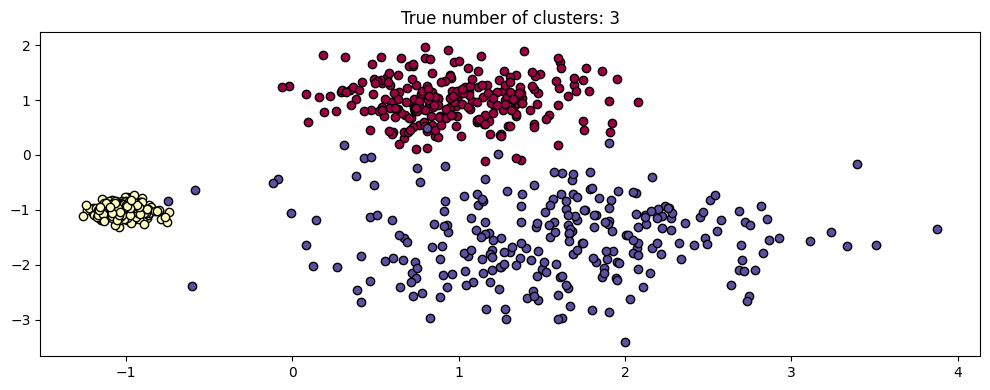

In [4]:
centers = [[1, 1], [-1, -1], [1.5, -1.5]]
X, labels_true = make_blobs(
    n_samples=750, centers=centers, cluster_std=[0.4, 0.1, 0.75], random_state=0
)

plot(X, labels=labels_true, ground_truth=True)

# **Langkah 4: Uji Scale Invariance pada DBSCAN**

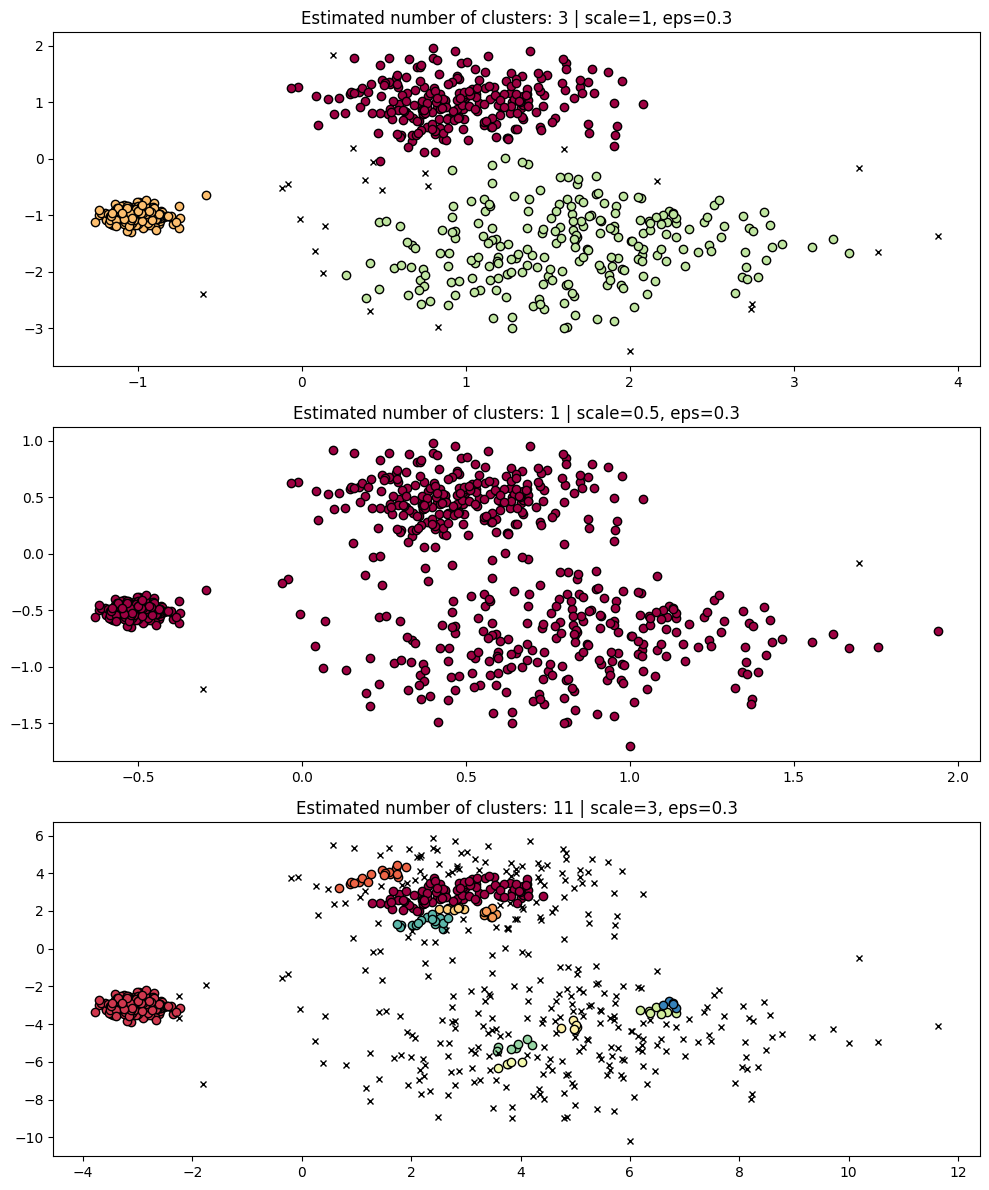

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
dbs = DBSCAN(eps=0.3)
for idx, scale in enumerate([1, 0.5, 3]):
    dbs.fit(X * scale)
    plot(X * scale, dbs.labels_, parameters={"scale": scale, "eps": 0.3}, ax=axes[idx])

## **Mengubah eps sesuai skala**

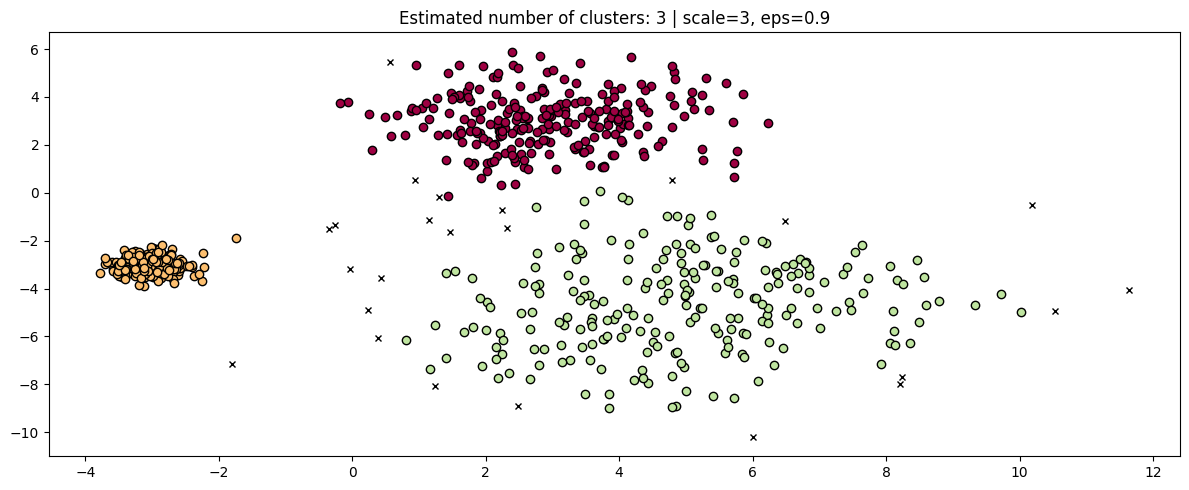

In [6]:
fig, axis = plt.subplots(1, 1, figsize=(12, 5))
dbs = DBSCAN(eps=0.9).fit(3 * X)
plot(3 * X, dbs.labels_, parameters={"scale": 3, "eps": 0.9}, ax=axis)

# **Langkah 5: Bandingkan dengan HDBSCAN (lebih robust)**

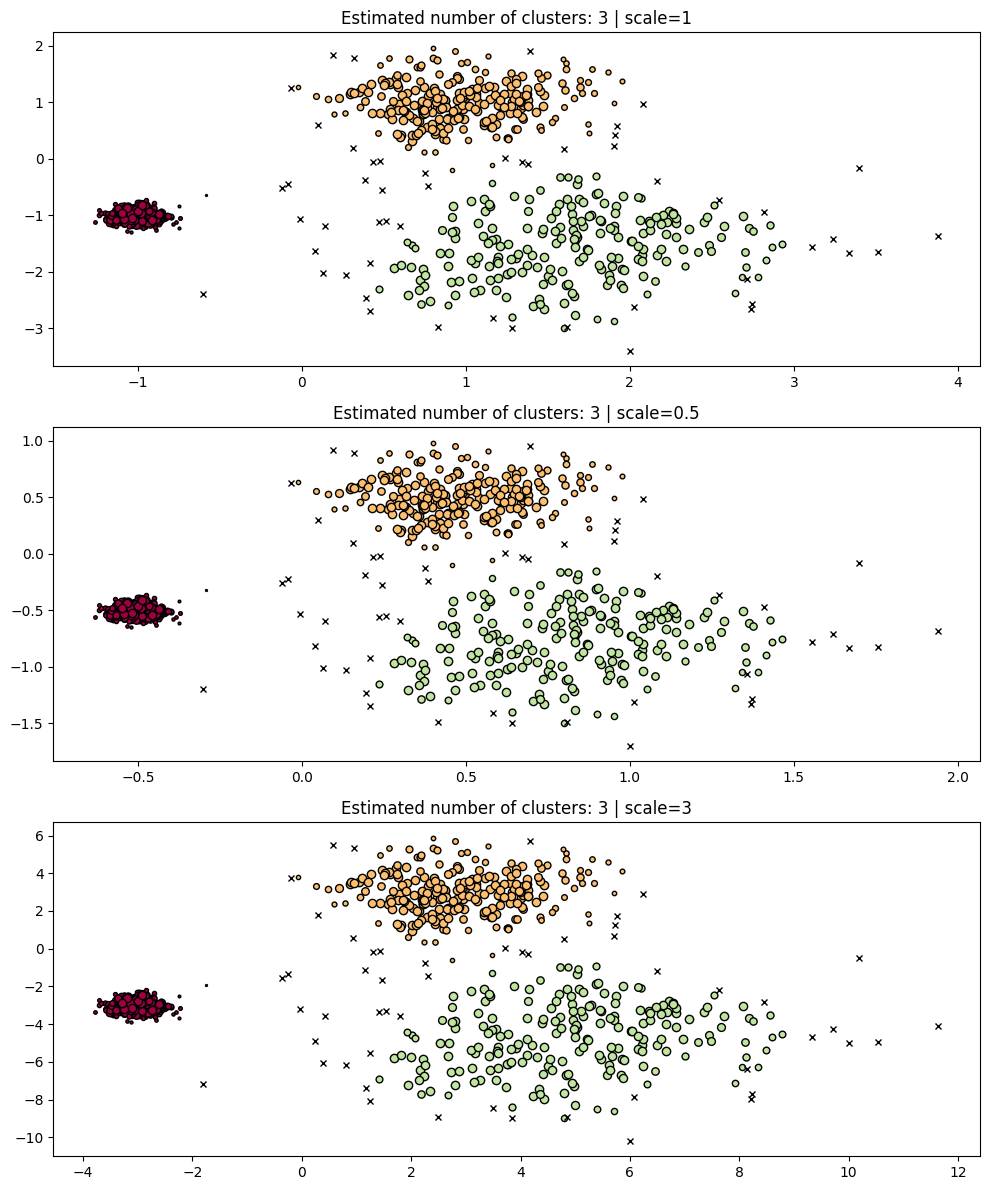

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
hdb = hdbscan.HDBSCAN()
for idx, scale in enumerate([1, 0.5, 3]):
    hdb.fit(X * scale)
    plot(X * scale, hdb.labels_, hdb.probabilities_, ax=axes[idx], parameters={"scale": scale})

# **Langkah 6: Multi-Scale Clustering**

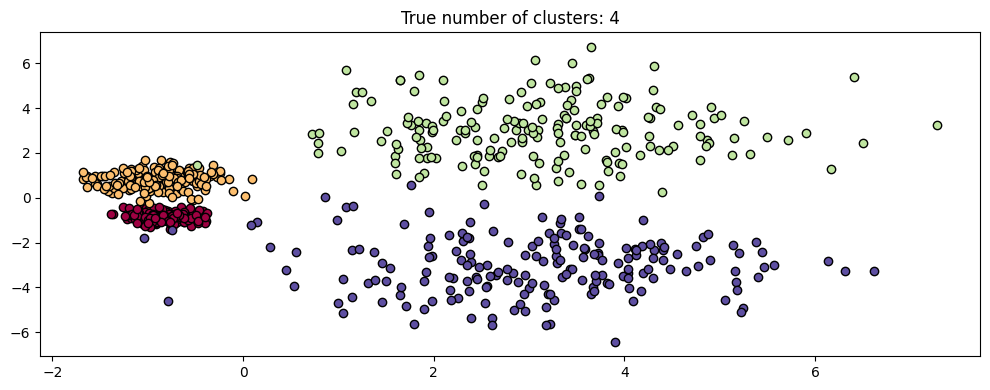

In [8]:
centers = [[-0.85, -0.85], [-0.85, 0.85], [3, 3], [3, -3]]
X, labels_true = make_blobs(
    n_samples=750, centers=centers, cluster_std=[0.2, 0.35, 1.35, 1.35], random_state=0
)
plot(X, labels=labels_true, ground_truth=True)

# **Membandingkan DBSCAN dengan eps berbeda**

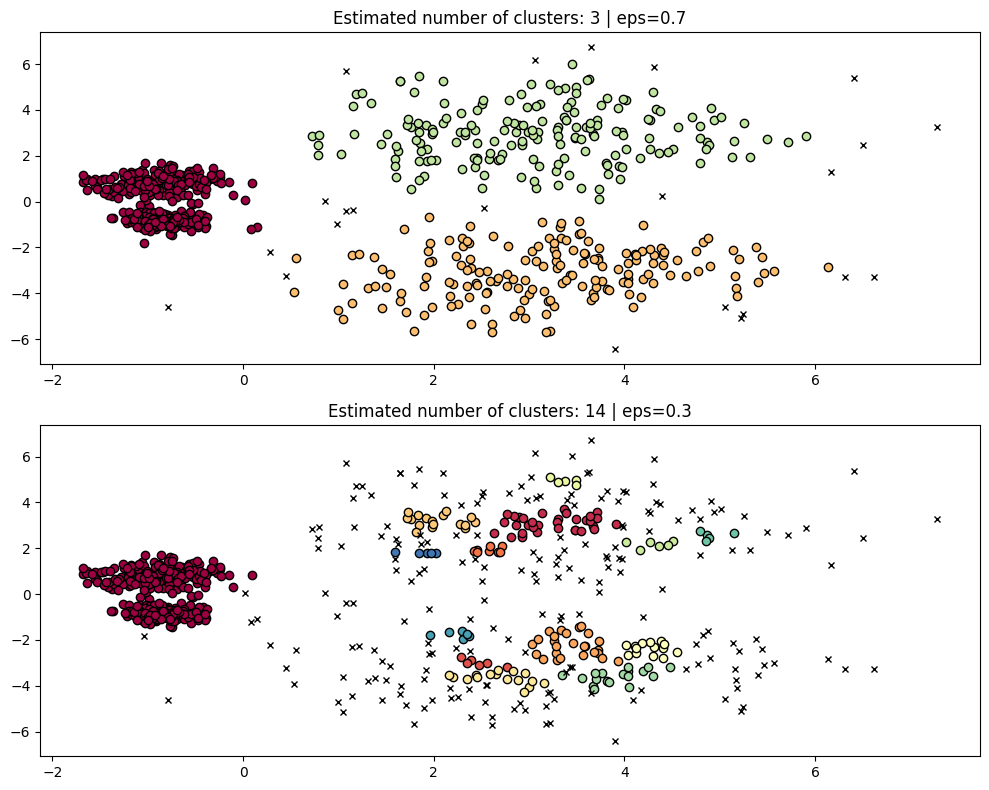

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8))
params = {"eps": 0.7}
dbs = DBSCAN(**params).fit(X)
plot(X, dbs.labels_, parameters=params, ax=axes[0])

params = {"eps": 0.3}
dbs = DBSCAN(**params).fit(X)
plot(X, dbs.labels_, parameters=params, ax=axes[1])

# **Run HDBSCAN**

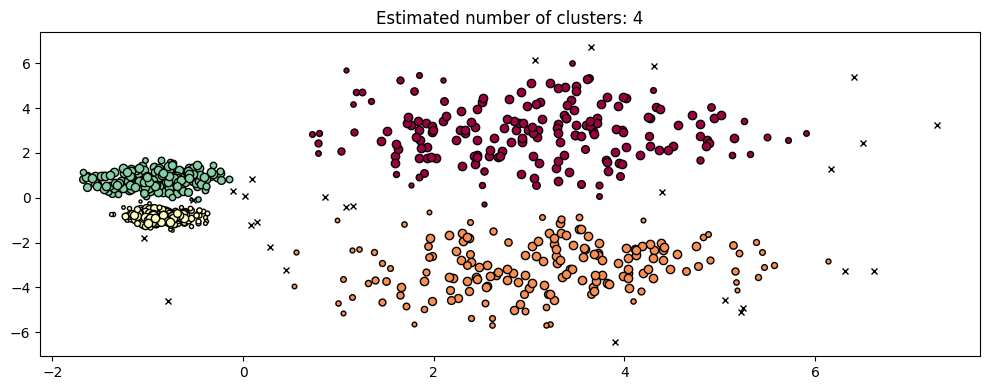

In [10]:
hdb = hdbscan.HDBSCAN().fit(X)
plot(X, hdb.labels_, hdb.probabilities_)

# **Langkah 7: Eksperimen Hyperparameter min_cluster_size**

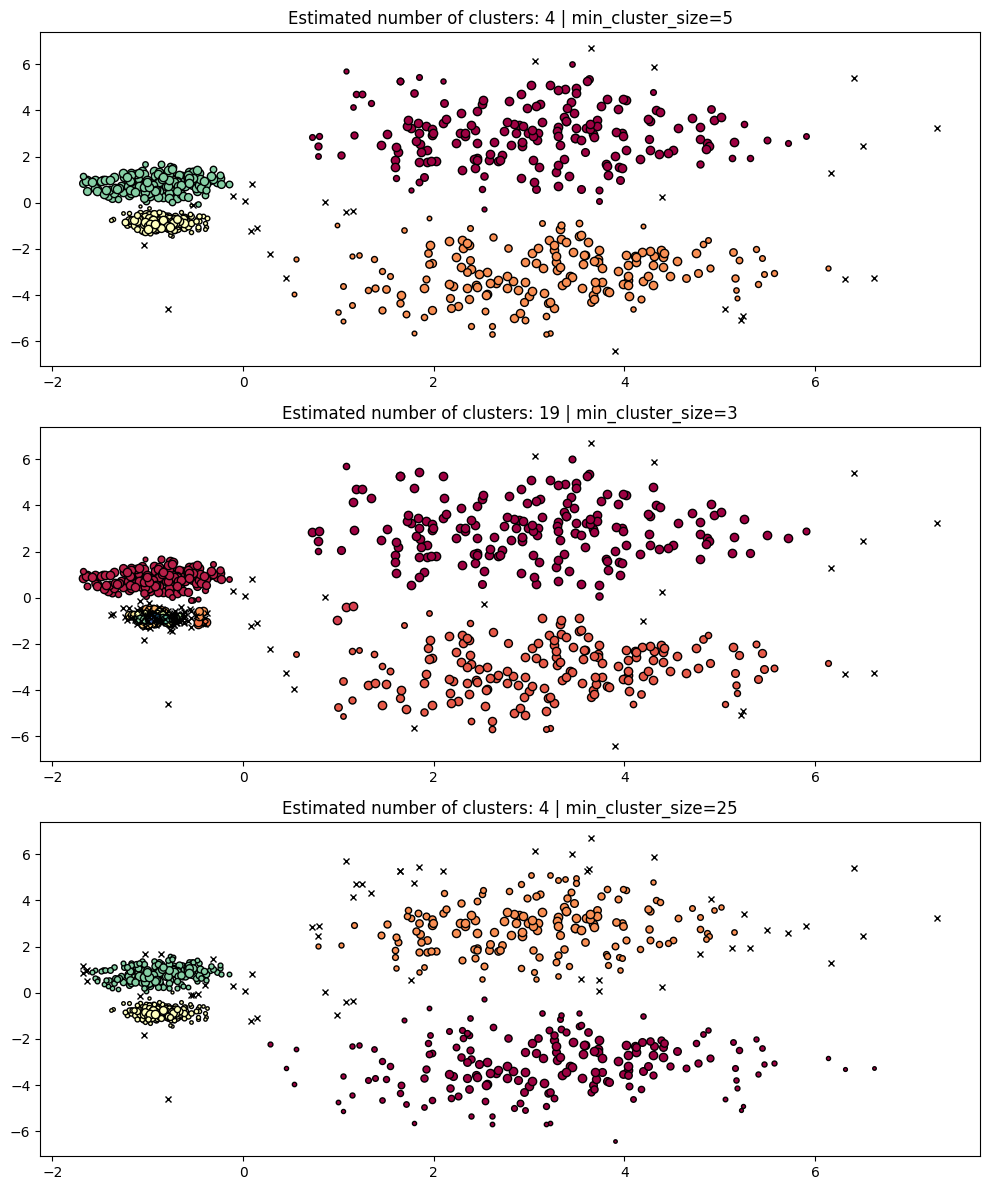

In [11]:
PARAM = ({"min_cluster_size": 5}, {"min_cluster_size": 3}, {"min_cluster_size": 25})
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
for i, param in enumerate(PARAM):
    hdb = hdbscan.HDBSCAN(**param).fit(X)
    plot(X, hdb.labels_, hdb.probabilities_, param, ax=axes[i])

# **Langkah 8: Eksperimen Hyperparameter min_samples**

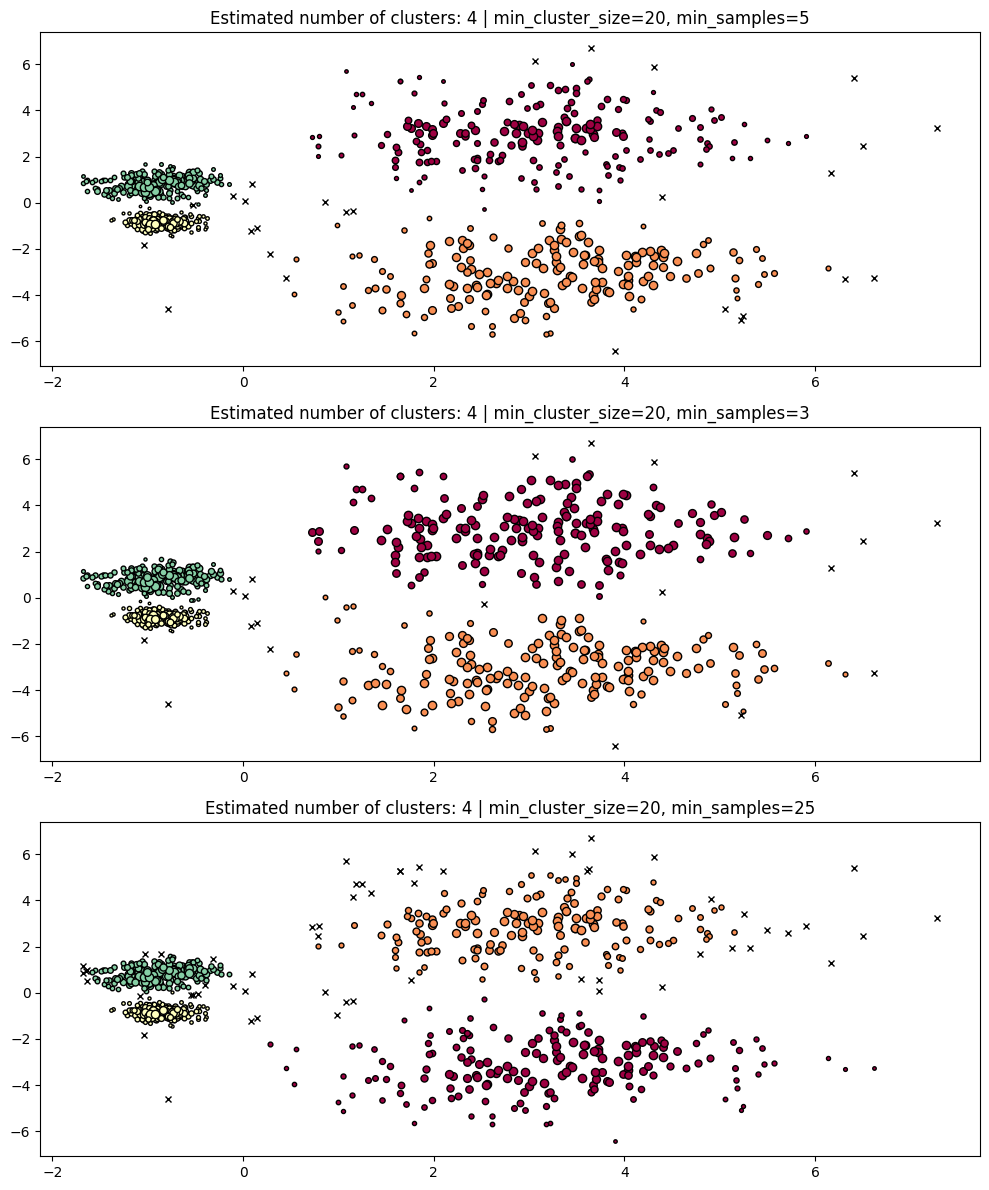

In [12]:
PARAM = (
    {"min_cluster_size": 20, "min_samples": 5},
    {"min_cluster_size": 20, "min_samples": 3},
    {"min_cluster_size": 20, "min_samples": 25},
)
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
for i, param in enumerate(PARAM):
    hdb = hdbscan.HDBSCAN(**param).fit(X)
    plot(X, hdb.labels_, hdb.probabilities_, param, ax=axes[i])

# **Langkah 9: DBSCAN Clustering dari Pohon HDBSCAN**

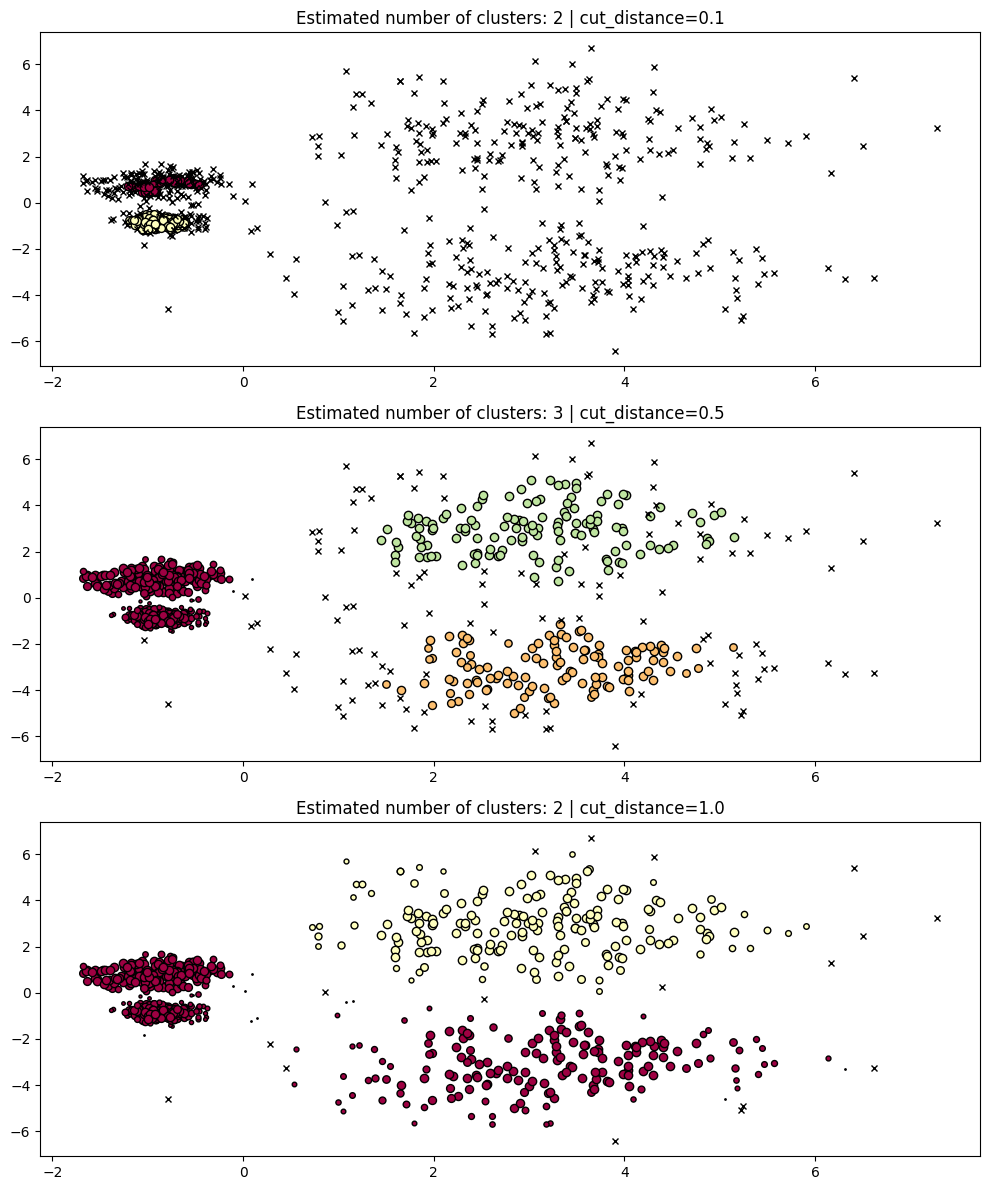

In [13]:
PARAM = (
    {"cut_distance": 0.1},
    {"cut_distance": 0.5},
    {"cut_distance": 1.0},
)
hdb = hdbscan.HDBSCAN().fit(X)
fig, axes = plt.subplots(len(PARAM), 1, figsize=(10, 12))
for i, param in enumerate(PARAM):
    labels = hdb.dbscan_clustering(**param)
    plot(X, labels, hdb.probabilities_, param, ax=axes[i])

# **Langkah 10: Evaluasi dengan Silhouette Score**

In [14]:
from sklearn.metrics import silhouette_score

# Menghitung Silhouette Score untuk hasil clustering HDBSCAN
sil_score = silhouette_score(X, hdb.labels_)
print(f"Silhouette Score: {sil_score}")

Silhouette Score: 0.5743816709862986


# **Langkah 11: Evaluasi dengan Davies-Bouldin Index**

In [15]:
from sklearn.metrics import davies_bouldin_score

# Menghitung Davies-Bouldin Index untuk hasil clustering HDBSCAN
dbi_score = davies_bouldin_score(X, hdb.labels_)
print(f"Davies-Bouldin Index: {dbi_score}")

Davies-Bouldin Index: 1.6436030674842066


# **Langkah 12: Visualisasi Hasil Evaluasi**

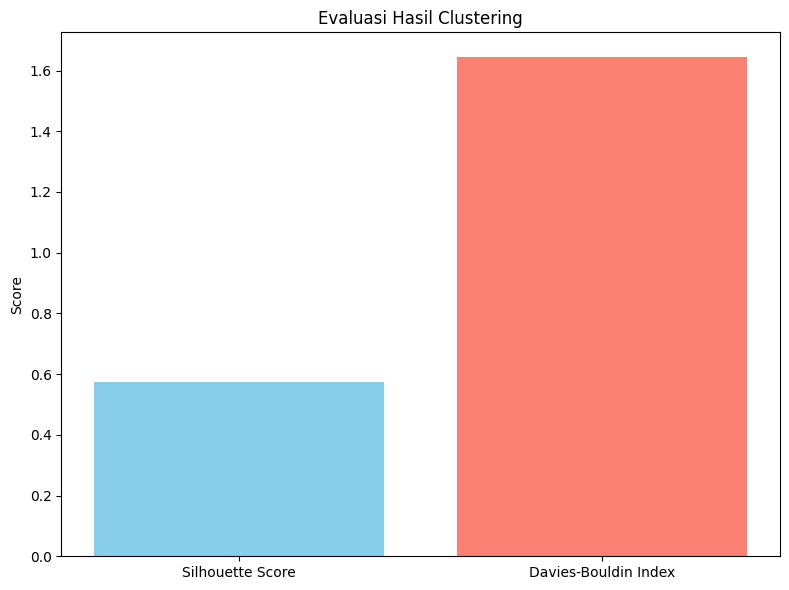

In [16]:
# Misalnya kita ingin membandingkan DBI dan Silhouette Score untuk beberapa eksperimen
scores = {
    "Silhouette Score": sil_score,
    "Davies-Bouldin Index": dbi_score
}

# Plot hasil evaluasi
fig, ax = plt.subplots(figsize=(8, 6))
ax.bar(scores.keys(), scores.values(), color=['skyblue', 'salmon'])
ax.set_title("Evaluasi Hasil Clustering")
ax.set_ylabel("Score")
plt.tight_layout()
plt.show()

# **TUGAS - Klasterisasi Hierarki**

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from scipy.spatial.distance import cdist

import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")

In [20]:
# Membaca file CSV dengan pandas
df = pd.read_csv("/content/drive/MyDrive/PBL/lettuce_dataset_updated.csv", encoding="latin-1")
df.head()

,Plant_ID,Date,Temperature (°C),Humidity (%),TDS Value (ppm),pH Level,Growth Days,Temperature (F),Humidity
0,1,8/3/2023,33.4,53,582,6.4,1,92.12,0.53
1,1,8/4/2023,33.5,53,451,6.1,2,92.30,0.53
2,1,8/5/2023,33.4,59,678,6.4,3,92.12,0.59
3,1,8/6/2023,33.4,68,420,6.4,4,92.12,0.68
4,1,8/7/2023,33.4,74,637,6.5,5,92.12,0.74


In [22]:
  # Pilih kolom numerik saja yang ingin di-scaling
  features = ['Temperature (°C)', 'Humidity (%)', 'TDS Value (ppm)', 'pH Level', 'Growth Days']
  X_raw = df[features]

  scaler = StandardScaler()
  X_scaled = scaler.fit_transform(X_raw)

Menentukan Cluster menggunakan dendogram

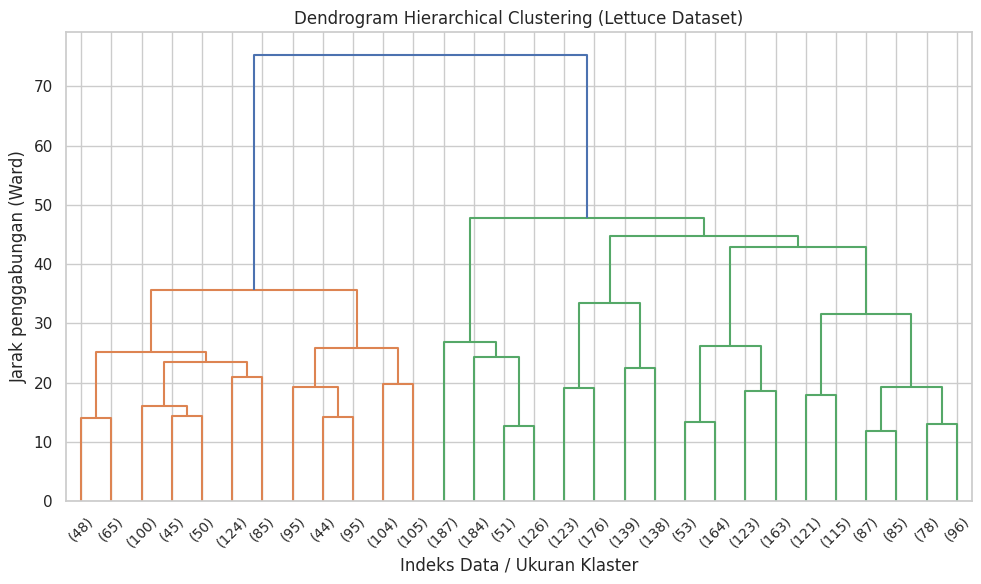

In [23]:
from scipy.cluster.hierarchy import linkage, dendrogram

# Membentuk linkage untuk visualisasi dendrogram
Z = linkage(
    X_scaled,
    method="ward",
    metric="euclidean"
)

plt.figure(figsize=(10, 6))
# Menggunakan truncate_mode agar dendrogram rapi dan tidak terlalu padat karena data berjumlah 3169 baris
dendrogram(Z, truncate_mode='lastp', p=30)
plt.title("Dendrogram Hierarchical Clustering (Lettuce Dataset)")
plt.xlabel("Indeks Data / Ukuran Klaster")
plt.ylabel("Jarak penggabungan (Ward)")
plt.tight_layout()
plt.show()

# **Menerapkan HDBSCAN**

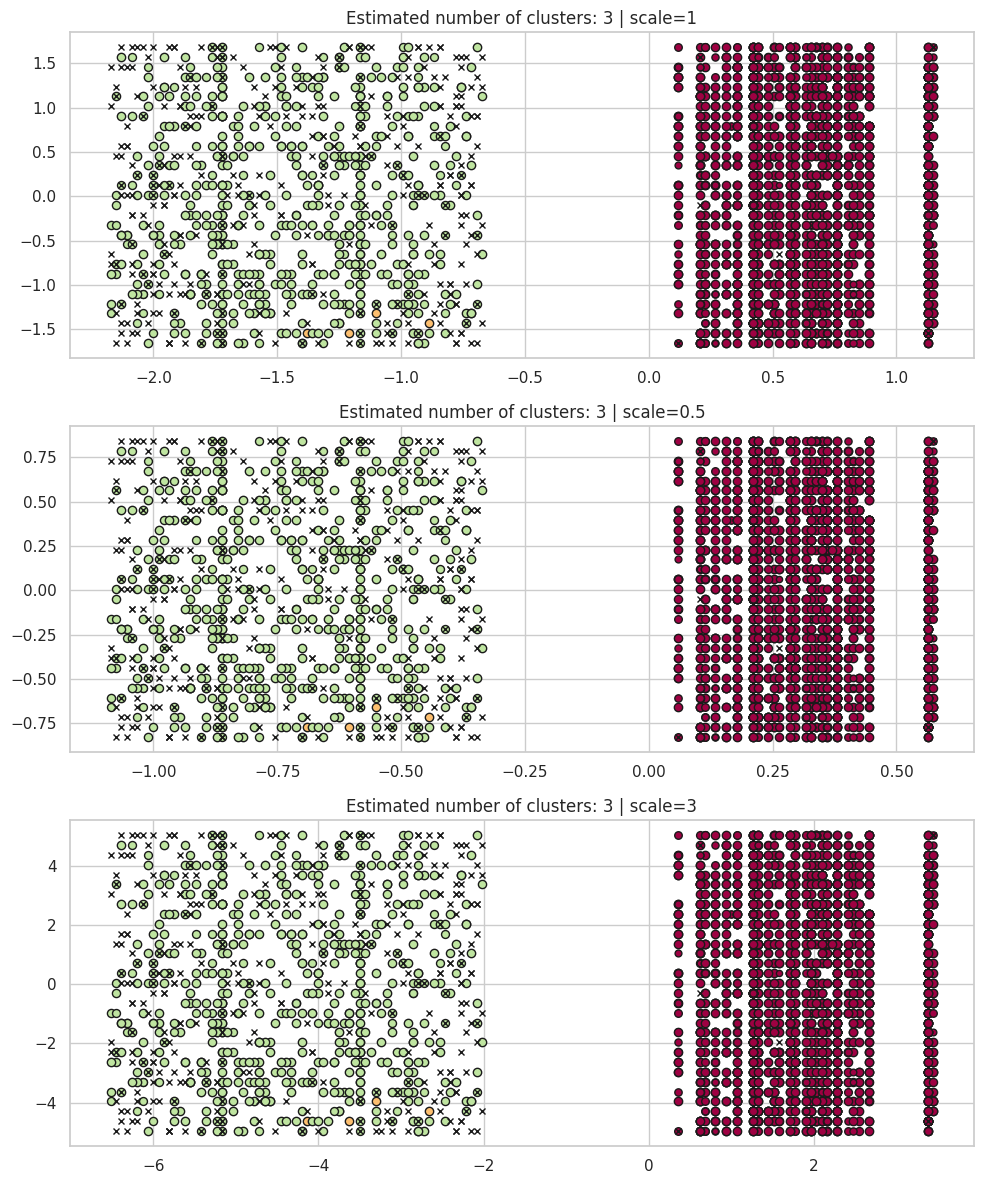

In [28]:
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
hdb = hdbscan.HDBSCAN()
for idx, scale in enumerate([1, 0.5, 3]):
    hdb.fit(X_scaled * scale)
    plot(X_scaled * scale, hdb.labels_, hdb.probabilities_, ax=axes[idx], parameters={"scale": scale})

In [27]:
import hdbscan

# Inisialisasi dan fit HDBSCAN pada dataset selada (X_scaled)
hdb_lettuce = hdbscan.HDBSCAN()
hdb_lettuce.fit(X_scaled)

# Label -1 merepresentasikan noise
labels = hdb_lettuce.labels_
jumlah_noise = list(labels).count(-1)
jumlah_klaster = len(set(labels)) - (1 if -1 in labels else 0)

print(f"Jumlah Klaster Terbentuk: {jumlah_klaster}")
print(f"Jumlah Noise (Outlier): {jumlah_noise} dari {len(labels)} data")

Jumlah Klaster Terbentuk: 3
Jumlah Noise (Outlier): 335 dari 3169 data


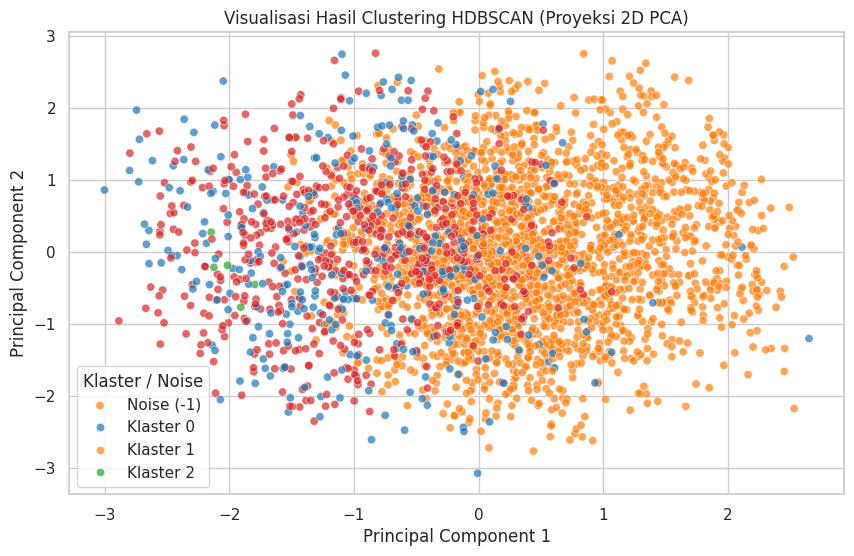

In [29]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

# Reduksi dimensi menggunakan PCA menjadi 2 Komponen Utama
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Visualisasi hasil HDBSCAN menggunakan PCA
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=labels,
    palette="tab10",
    legend="full",
    alpha=0.7
)
plt.title("Visualisasi Hasil Clustering HDBSCAN (Proyeksi 2D PCA)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Klaster / Noise", labels=["Noise (-1)", "Klaster 0", "Klaster 1", "Klaster 2"])
plt.show()

### **Analisis Singkat: Apakah hasil clustering HDBSCAN sesuai dengan label asli dataset tersebut?**

1. **Struktur Klaster Terbentuk:**
   - **HDBSCAN** membagi dataset selada ke dalam **3 klaster** utama dengan **335 data noise/outlier**.

2. **Kesesuaian dengan Label Asli (`Plant_ID`):**
   - Jika kita melihat struktur kolom dataset, kolom `Plant_ID` bernilai numerik yang merujuk pada nomor tanaman/eksperimen tertentu.
   - Secara umum, hasil clustering **tidak akan 100% sama persis** dengan `Plant_ID` karena algoritma mengelompokkan data berdasarkan karakteristik lingkungan hidup tanaman (`Temperature`, `Humidity`, `TDS`, `pH`, `Growth Days`) di tiap fase waktu, sedangkan `Plant_ID` sekadar identitas tanaman.
   - Namun, HDBSCAN berhasil mengidentifikasi 3 klaster alami yang merepresentasikan variasi fase pertumbuhan atau kondisi lingkungan yang dominan (misalnya fase awal vs fase akhir pertumbuhan yang membutuhkan kadar nutrisi/TDS yang berbeda).